# Task B - Multiclass Random Forest

**Mục tiêu:** Phân loại 4 lớp: Benign, Ransomware, Spyware, Trojan. Topic 05, mục B/D.

**Thuật toán:** RF lấy trung bình xác suất của 300 cây với `max_depth=20`, `seed=42` (`rf_300_d20`) để tái lập.

**Cách dùng:** chạy lần lượt từ trên xuống (Run All). Các cell tiêu đề *🔎 Xem* hiển thị bảng, biểu đồ và số liệu.

> Cấu hình chính của Task B Multiclass RF: `rf_300_d20`, ngưỡng từ chối dự đoán `tau = 0.70`.

## 1. Setup
Nạp thư viện, tìm project root, đọc cấu hình và định nghĩa hàm nạp dữ liệu.

### 1.1 Thư viện

In [1]:
import sys, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)
from sklearn.ensemble import RandomForestClassifier

### 1.2 Tìm project root & import preprocessing

In [2]:
# Tìm project root (thư mục chứa preprocessing_data/preprocessing.py)
ROOT = Path.cwd().resolve()
while not (ROOT / 'preprocessing_data' / 'preprocessing.py').is_file() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / 'preprocessing_data' / 'preprocessing.py').is_file():
    raise RuntimeError('Mở notebook từ project root hoặc TESTNOTEBOOK/.')

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from preprocessing_data.preprocessing import make_preprocessor, SPLIT_DIR

### 1.3 Cấu hình & hàm nạp dữ liệu

In [3]:
# Cấu hình đã freeze
ALGORITHM = 'random_forest'
TASK      = 'multiclass'
SELECTED_MODEL = 'rf_300_d20'
SELECTED_TAU   = 0.7

protocol = json.loads((ROOT / 'model/configs/task_b_baselines.json').read_text(encoding='utf-8-sig'))

CSV_FILES = {'train': 'train.csv', 'validation': 'dev.csv', 'test': 'test.csv'}

def load_split_csv(split):
    frame = pd.read_csv(SPLIT_DIR / CSV_FILES[split]).set_index('row_index')
    labels = frame['Class' if TASK == 'binary' else 'multiclass']
    features = frame.drop(columns=['Class', 'multiclass', 'Category', 'group_id', 'split'], errors='ignore')
    return features, labels

classifier = RandomForestClassifier(**protocol['models'][ALGORITHM])

## 2. Nạp dữ liệu
Đọc train/validation từ CSV, tách features và nhãn. `Class/Category/identifier` không nằm trong X.

In [4]:
X_train, y_train = load_split_csv('train')
X_val, y_val = load_split_csv('validation')

features = list(X_train.columns)

### 🔎 Xem: số mẫu mỗi lớp

In [5]:
print(pd.DataFrame({'train': y_train.value_counts(), 'validation': y_val.value_counts()}))
print('Features:', len(features))

            train  validation
multiclass                   
Benign      20508        4395
Spyware      7012        1504
Ransomware   6853        1469
Trojan       6640        1424
Features: 55


## 3. Pipeline + huấn luyện
Median imputation → IQR (chỉ đánh dấu outlier, không đổi giá trị) → StandardScaler → RandomForest. Chỉ fit trên **train**.

In [6]:
pipeline = Pipeline([('preprocessing', make_preprocessor()), ('classifier', classifier)])

t0 = time.perf_counter()
pipeline.fit(X_train, y_train)   # chỉ fit trên train
train_seconds = time.perf_counter() - t0

### 🔎 Xem: thời gian train

In [7]:
print('Train seconds:', round(train_seconds, 2))

Train seconds: 1.37


## 4. Dự đoán validation + metrics
Tính xác suất, kiểm tra hợp lệ, tính metrics và confusion matrix (macro-F1 là chỉ số chính).

### 4.1 Dự đoán xác suất

In [8]:
classes = pipeline.classes_.tolist()

probabilities = pipeline.predict_proba(X_val)
predicted = np.asarray(classes)[probabilities.argmax(axis=1)]

### 4.2 Metrics & confusion matrix

In [9]:
report  = classification_report(y_val, predicted, labels=classes, output_dict=True, zero_division=0)
metrics = {
    'accuracy':     accuracy_score(y_val, predicted),
    'macro_f1':     f1_score(y_val, predicted, average='macro'),
    'weighted_f1':  f1_score(y_val, predicted, average='weighted'),
    'macro_recall': recall_score(y_val, predicted, average='macro'),
}
cm = confusion_matrix(y_val, predicted, labels=classes)

### 🔎 Xem: báo cáo phân loại + tóm tắt metrics

In [10]:
print(pd.DataFrame(report).T)
print(metrics)

              precision    recall  f1-score      support
Benign         0.997956  1.000000  0.998977  4395.000000
Ransomware     0.641304  0.642614  0.641959  1469.000000
Spyware        0.762006  0.717420  0.739041  1504.000000
Trojan         0.653333  0.688202  0.670315  1424.000000
accuracy       0.841447  0.841447  0.841447     0.841447
macro avg      0.763650  0.762059  0.762573  8792.000000
weighted avg   0.842186  0.841447  0.841627  8792.000000
{'accuracy': 0.8414467697907189, 'macro_f1': 0.7625728518448546, 'weighted_f1': 0.8416273336003565, 'macro_recall': 0.7620591207754913}


### 🔎 Xem: confusion matrix (hàng = nhãn thật, cột = dự đoán)

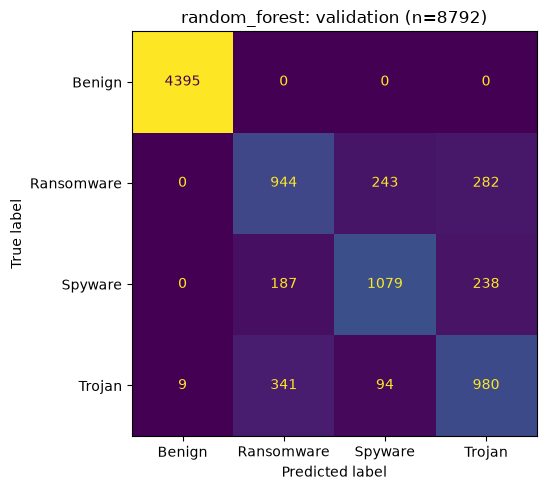

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, colorbar=False)
ax.set_title(f'{ALGORITHM}: validation (n={len(y_val)})')
fig.tight_layout()
plt.show()

## 5. Khảo sát ngưỡng từ chối (tau)
Mẫu có `p_max < tau` bị coi là `Uncertain`. Coverage = số mẫu được nhận / tổng.

### 5.1 Hàm `coverage_at` & đường cong coverage – accuracy

In [12]:
def coverage_at(tau, scores, correct):
    """Coverage và accuracy trên các mẫu được nhận (p_max >= tau)."""
    accepted = scores >= tau
    count    = int(accepted.sum())
    return {
        'tau':               float(tau),
        'accepted':          count,
        'coverage':          count / len(scores),
        'accepted_accuracy': float(correct[accepted].mean()) if count else None,
    }

confidence       = probabilities.max(axis=1)
correct          = y_val.to_numpy() == predicted
coverage_results = [coverage_at(t, confidence, correct) for t in protocol['tau_grid']]
curve            = pd.DataFrame(coverage_results)

### 🔎 Xem: bảng coverage – accuracy theo tau

In [13]:
print(curve.to_string(index=False))

 tau  accepted  coverage  accepted_accuracy
0.00      8792  1.000000           0.841447
0.50      7803  0.887511           0.891452
0.55      7349  0.835874           0.909103
0.60      6911  0.786056           0.931124
0.65      6509  0.740332           0.949455
0.70      6185  0.703480           0.963137
0.75      5896  0.670610           0.974220
0.80      5607  0.637739           0.982165
0.85      5342  0.607598           0.989143
0.90      5049  0.574272           0.994652
0.95      4811  0.547202           0.997090
0.99      4585  0.521497           0.999564
1.00      4378  0.497953           1.000000


### 🔎 Xem: biểu đồ coverage – accuracy

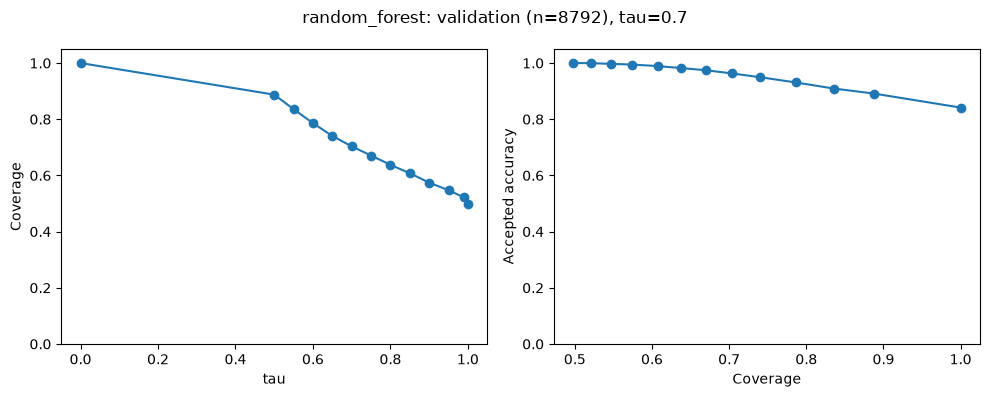

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(curve.tau, curve.coverage, marker='o')
axes[0].set(xlabel='tau', ylabel='Coverage', ylim=(0, 1.05))
axes[1].plot(curve.coverage, curve.accepted_accuracy, marker='o')
axes[1].set(xlabel='Coverage', ylabel='Accepted accuracy', ylim=(0, 1.05))
fig.suptitle(f'{ALGORITHM}: validation (n={len(y_val)}), tau={SELECTED_TAU}')
fig.tight_layout()
plt.show()

## 6. Feature importance
Importance **toàn cục** của mô hình đã train, không phải giải thích cho từng mẫu.

In [15]:
importance = (
    pd.DataFrame({'feature': features, 'importance': pipeline['classifier'].feature_importances_})
    .sort_values('importance', ascending=False, kind='stable')
)

### 🔎 Xem: Top-10 feature importance (mean decrease impurity (RF))

In [16]:
print(importance.head(10).to_string(index=False))

                        feature  importance
              svcscan.nservices    0.084421
         svcscan.kernel_drivers    0.070527
svcscan.shared_process_services    0.068464
   handles.avg_handles_per_proc    0.057583
      dlllist.avg_dlls_per_proc    0.055904
            pslist.avg_handlers    0.054267
                 handles.nevent    0.050540
                handles.nmutant    0.046726
               handles.nsection    0.039904
                  dlllist.ndlls    0.037853


## 7. Đánh giá test cuối
Sau khi chốt model/tau bằng validation, đánh giá một lần trên test bằng pipeline đang có trong bộ nhớ.

In [17]:
X_test, y_test = load_split_csv('test')

test_proba     = pipeline.predict_proba(X_test)
test_scores    = test_proba.max(axis=1)
test_predicted = np.asarray(classes)[test_proba.argmax(axis=1)]
actual         = y_test.to_numpy()
test_correct   = test_predicted == actual
test_accepted  = test_scores >= SELECTED_TAU

test_report = classification_report(actual, test_predicted, labels=classes, output_dict=True, zero_division=0)

by_class = {}
for label in classes:
    in_class = actual == label
    received = in_class & test_accepted
    by_class[label] = {
        "support": int(in_class.sum()),
        "accepted": int(received.sum()),
        "coverage": float(test_accepted[in_class].mean()) if in_class.any() else None,
        "accepted_accuracy": float(test_correct[received].mean()) if received.any() else None,
    }

acc = float(test_correct[test_accepted].mean()) if test_accepted.any() else None

print(f"{TASK} | RandomForest | test n={len(actual)} | tau={SELECTED_TAU}")
print(f"Accuracy={accuracy_score(actual, test_predicted):.4%} | Macro-F1={test_report['macro avg']['f1-score']:.6f}")
print(f"Coverage={test_accepted.mean():.4%} | Uncertain={int((~test_accepted).sum())}")
print("Accepted accuracy =", f"{acc:.4%}" if acc is not None else "N/A")
print(pd.DataFrame(by_class).T)

multiclass | RandomForest | test n=8791 | tau=0.7
Accuracy=83.9040% | Macro-F1=0.758832
Coverage=71.3002% | Uncertain=2523
Accepted accuracy = 95.2138%
            support  accepted  coverage  accepted_accuracy
Benign       4395.0    4393.0  0.999545           1.000000
Ransomware   1469.0     508.0  0.345813           0.795276
Spyware      1504.0     724.0  0.481383           0.906077
Trojan       1423.0     643.0  0.451862           0.800933


In [18]:
# Xuất model/reports/model_report.json: một báo cáo chung cho cả bốn notebook.
# Cập nhật mục của model đang chạy và giữ kết quả của các model đã chạy trước đó.
report_path = ROOT / 'model' / 'reports' / 'model_report.json'
report_path.parent.mkdir(parents=True, exist_ok=True)
combined_report = json.loads(report_path.read_text(encoding='utf-8')) if report_path.exists() else {}
model_id = '03_multiclass_random_forest'

combined_report[model_id] = {
    'task': TASK,
    'algorithm': ALGORITHM,
    'selected_config': SELECTED_MODEL,
    'classifier_params': pipeline.named_steps['classifier'].get_params(),
    'tau': SELECTED_TAU,
    'feature_count': len(features),
    'classes': classes,
    'validation': {
        'rows': len(y_val),
        'metrics': metrics,
        'classification_report': report,
        'confusion_matrix': cm.tolist(),
        'at_selected_tau': coverage_at(SELECTED_TAU, confidence, correct),
        'threshold_curve': coverage_results,
        'feature_importance': importance.to_dict(orient='records'),
    },
    'test': {
        'rows': len(y_test),
        'accuracy': float(accuracy_score(actual, test_predicted)),
        'classification_report': test_report,
        'confusion_matrix': confusion_matrix(actual, test_predicted, labels=classes).tolist(),
        'at_selected_tau': coverage_at(SELECTED_TAU, test_scores, test_correct),
        'uncertain': int((~test_accepted).sum()),
        'at_selected_tau_by_class': by_class,
    },
}

# Ghi qua file tạm để lần ghi bị gián đoạn không làm hỏng báo cáo hiện có.
temp_path = report_path.with_suffix('.json.tmp')
temp_path.write_text(
    json.dumps(combined_report, ensure_ascii=False, indent=2, sort_keys=True, allow_nan=False) + '\n',
    encoding='utf-8',
)
temp_path.replace(report_path)
print(f'Đã cập nhật {model_id} trong {report_path.relative_to(ROOT)}')


Đã cập nhật 03_multiclass_random_forest trong model\reports\model_report.json


In [19]:
# Xuất fitted pipeline .joblib vào model/artifacts/ theo cấu hình inference.
import joblib
from tempfile import NamedTemporaryFile

inference_config = json.loads((ROOT / 'model/configs/inference.json').read_text(encoding='utf-8'))
artifact_path = ROOT / inference_config['models'][model_id]['artifact']
artifact_path.parent.mkdir(parents=True, exist_ok=True)

with NamedTemporaryFile(dir=artifact_path.parent, suffix='.tmp', delete=False) as temp_file:
    temp_artifact = Path(temp_file.name)
try:
    joblib.dump(pipeline, temp_artifact)
    temp_artifact.replace(artifact_path)
finally:
    temp_artifact.unlink(missing_ok=True)

print(f'Đã xuất pipeline: {artifact_path.relative_to(ROOT)}')


Đã xuất pipeline: model\artifacts\03_multiclass_random_forest.joblib
